# Surf Maneuver Recognition: Session-Grouped Split

The original split assigns clips to train, validation and test at random, so clips from the same session
(same surfer, spot and camera) end up on both sides (see `01_data_exploration.ipynb`, sections 6 to 8).
This notebook groups clips into sessions using visual similarity between consecutive clips,
then builds a new split where every session belongs to a single subset.

## 1. Clip table

The clip inventory is shared with the other notebooks through `src/data/inventory.py`.

In [9]:
import sys
from pathlib import Path

import pandas as pd

# Make the project root importable, so the notebook can use the code in src/
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data.inventory import build_clip_table

df = build_clip_table()
print(len(df), "clips")
df["source"].value_counts()

1062 clips


source
sequence_space         634
sequence_underscore    379
roller                  45
360                      4
Name: count, dtype: int64

## 2. Visual embeddings

Each clip is described by a DINOv2 embedding ([`facebook/dinov2-small`](https://huggingface.co/facebook/dinov2-small), Apache 2.0):
a 384-dimensional vector summarizing how the scene looks (sea, light, colors, framing).
To reduce noise from any single frame, we average the embeddings of three frames (25%, 50% and 75% of the clip).

In [4]:
import numpy as np
import torch
from transformers import AutoImageProcessor, AutoModel

from src.data.video import read_frame

MODEL_ID = "facebook/dinov2-small"
device = "cuda" if torch.cuda.is_available() else "cpu"

# The processor resizes and normalizes images the way the model was trained
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModel.from_pretrained(MODEL_ID).to(device).eval()
print("device:", device)

c:\Users\fabri\Desktop\Portfolio\surf-maneuver-recognition\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1115 13:38:12.169000 228 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
c:\Users\fabri\Desktop\Portfolio\surf-maneuver-recognition\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\fabri\.cache\huggingface\hub\models--facebook--dinov2-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For 

device: cuda


In [5]:
EMBEDDINGS_FILE = PROJECT_ROOT / "data" / "processed" / "dinov2_small_frame_embeddings.npz"
POSITIONS = (0.25, 0.5, 0.75)

# Computing takes a few minutes, so results are cached; the file list guards against stale caches
if EMBEDDINGS_FILE.exists() and list(np.load(EMBEDDINGS_FILE)["files"]) == df["file"].tolist():
    embeddings = np.load(EMBEDDINGS_FILE)["embeddings"]
else:
    vectors = []
    with torch.inference_mode():
        for path in df["path"]:
            frames = [read_frame(path, p) for p in POSITIONS]
            inputs = processor(images=frames, return_tensors="pt").to(device)
            per_frame = model(**inputs).pooler_output   # one 384-d vector per frame
            vectors.append(per_frame.mean(dim=0).cpu().numpy())
    embeddings = np.stack(vectors)
    EMBEDDINGS_FILE.parent.mkdir(parents=True, exist_ok=True)
    np.savez(EMBEDDINGS_FILE, embeddings=embeddings, files=np.array(df["file"]))

# Unit length, so a dot product between two clips is their cosine similarity
embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
embeddings.shape

(1062, 384)

## 3. Similarity between consecutive clips

Within a source, clips are ordered by number and compared with the next one (cosine similarity).
Consecutive clips from the same session should be very similar; a sharp drop marks a session boundary.
Random pairs of clips, mostly from different sessions, give the reference for "not similar".

In [6]:
# Order clips by source and number; clips without a number (e.g. "360.mp4") have no neighbors
ordered = df.dropna(subset=["clip_number"]).sort_values(["source", "clip_number"]).copy()
rows = ordered.index.to_numpy()   # positions in df, which are also the rows of `embeddings`

# Cosine similarity of each clip with the next one (dot product of unit vectors)
sim = (embeddings[rows[:-1]] * embeddings[rows[1:]]).sum(axis=1)

# The last clip of each source has no "next" clip in the same source
next_is_same_source = (ordered["source"].to_numpy()[:-1] == ordered["source"].to_numpy()[1:])
ordered["sim_next"] = np.append(np.where(next_is_same_source, sim, np.nan), np.nan)

ordered["sim_next"].describe().round(3)

count    1056.000
mean        0.876
std         0.076
min         0.356
25%         0.847
50%         0.895
75%         0.928
max         1.000
Name: sim_next, dtype: float64

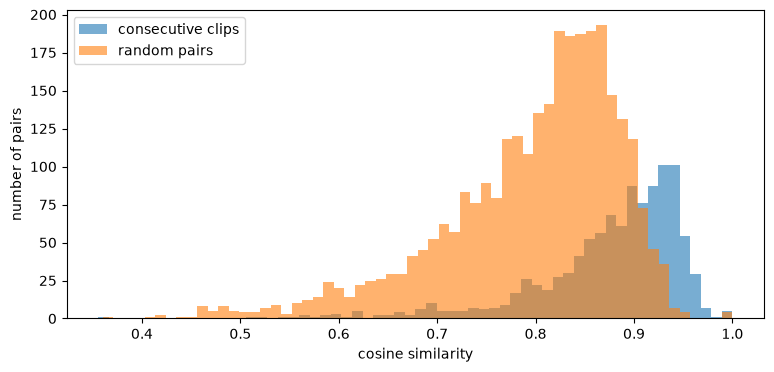

In [7]:
import matplotlib.pyplot as plt

# Reference: similarity between random pairs of clips (mostly different sessions)
rng = np.random.default_rng(0)
a, b = rng.integers(0, len(embeddings), size=(2, 3000))
random_sim = (embeddings[a] * embeddings[b]).sum(axis=1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ordered["sim_next"].dropna(), bins=60, alpha=0.6, label="consecutive clips")
ax.hist(random_sim, bins=60, alpha=0.6, label="random pairs")
ax.set_xlabel("cosine similarity")
ax.set_ylabel("number of pairs")
ax.legend()
plt.show()

The two distributions overlap heavily: every surf clip looks like every other surf clip (sea, foam, a person on a board),
so a single similarity threshold cannot separate sessions reliably. Consecutive clips are still more similar than random pairs
(median 0.895 vs about 0.83), which confirms that the numbering carries session information.
A few random pairs have a similarity close to 1.0, which suggests duplicate clips (next section).

## 4. Near-duplicate clips

Pairs of clips with almost identical embeddings anywhere in the dataset.
A duplicate in both train and test would be the most direct form of leakage.

In [12]:
# Similarity between every pair of clips (1062 x 1062 matrix)
sim_matrix = embeddings @ embeddings.T

# Upper triangle only (each pair once, no self-pairs), above a near-duplicate threshold
i, j = np.where(np.triu(sim_matrix, k=1) > 0.98)

dups = pd.DataFrame({
    "file_a": df["file"].to_numpy()[i], "split_a": df["split"].to_numpy()[i], "maneuver_a": df["maneuver"].to_numpy()[i],
    "file_b": df["file"].to_numpy()[j], "split_b": df["split"].to_numpy()[j], "maneuver_b": df["maneuver"].to_numpy()[j],
    "row_a": i, "row_b": j,
    "similarity": sim_matrix[i, j].round(4),
}).sort_values("similarity", ascending=False)

print(len(dups), "near-duplicate pairs;",
      (dups["split_a"] != dups["split_b"]).sum(), "across splits;",
      (dups["maneuver_a"] != dups["maneuver_b"]).sum(), "with different labels")
dups.head(10)

11 near-duplicate pairs; 5 across splits; 3 with different labels


,file_a,split_a,maneuver_a,file_b,split_b,maneuver_b,row_a,row_b,similarity
2,Séquence imbriquée 658.mp4,train,360,Séquence imbriquée 659.mp4,train,360,233,234,1.0000
4,Séquence_imbriquée_357.mp4,train,cutback-frontside,Séquence_imbriquée_357.mp4,train,roller,465,829,1.0000
3,Séquence_imbriquée_355.mp4,train,cutback-frontside,Séquence_imbriquée_355.mp4,train,roller,464,827,1.0000
10,Séquence imbriquée 760.mp4,train,take-off,Séquence imbriquée 761.mp4,train,take-off,915,916,1.0000
8,Séquence_imbriquée_311.mp4,train,roller,Séquence_imbriquée_43.mp4,val,roller,812,1047,1.0000
5,Séquence_imbriquée_362.mp4,train,cutback-frontside,Séquence_imbriquée_362.mp4,train,roller,467,832,1.0000
7,Séquence imbriquée 935.mp4,train,roller,Séquence imbriquée 596.mp4,val,roller,766,1014,0.9865
0,Séquence imbriquée 983.mp4,test,360,Séquence imbriquée 666.mp4,train,360,20,236,0.9856
9,Séquence_imbriquée_341.mp4,train,roller,Séquence_imbriquée_342.mp4,train,roller,824,825,0.9829
1,Séquence_imbriquée_268.mp4,test,roller,Roller_30.mp4,train,roller,169,521,0.9820


In [13]:
import hashlib

def file_hash(path):
    """MD5 of the file bytes: equal hashes mean byte-identical files."""
    return hashlib.md5(Path(path).read_bytes()).hexdigest()

dups["identical_file"] = [
    file_hash(df.loc[a, "path"]) == file_hash(df.loc[b, "path"])
    for a, b in zip(dups["row_a"], dups["row_b"])
]
dups[["file_a", "split_a", "maneuver_a", "file_b", "split_b", "maneuver_b", "similarity", "identical_file"]]

,file_a,split_a,maneuver_a,file_b,split_b,maneuver_b,similarity,identical_file
2,Séquence imbriquée 658.mp4,train,360,Séquence imbriquée 659.mp4,train,360,1.0000,False
4,Séquence_imbriquée_357.mp4,train,cutback-frontside,Séquence_imbriquée_357.mp4,train,roller,1.0000,True
3,Séquence_imbriquée_355.mp4,train,cutback-frontside,Séquence_imbriquée_355.mp4,train,roller,1.0000,True
10,Séquence imbriquée 760.mp4,train,take-off,Séquence imbriquée 761.mp4,train,take-off,1.0000,False
8,Séquence_imbriquée_311.mp4,train,roller,Séquence_imbriquée_43.mp4,val,roller,1.0000,False
5,Séquence_imbriquée_362.mp4,train,cutback-frontside,Séquence_imbriquée_362.mp4,train,roller,1.0000,True
7,Séquence imbriquée 935.mp4,train,roller,Séquence imbriquée 596.mp4,val,roller,0.9865,False
0,Séquence imbriquée 983.mp4,test,360,Séquence imbriquée 666.mp4,train,360,0.9856,False
9,Séquence_imbriquée_341.mp4,train,roller,Séquence_imbriquée_342.mp4,train,roller,0.9829,False
1,Séquence_imbriquée_268.mp4,test,roller,Roller_30.mp4,train,roller,0.9820,False


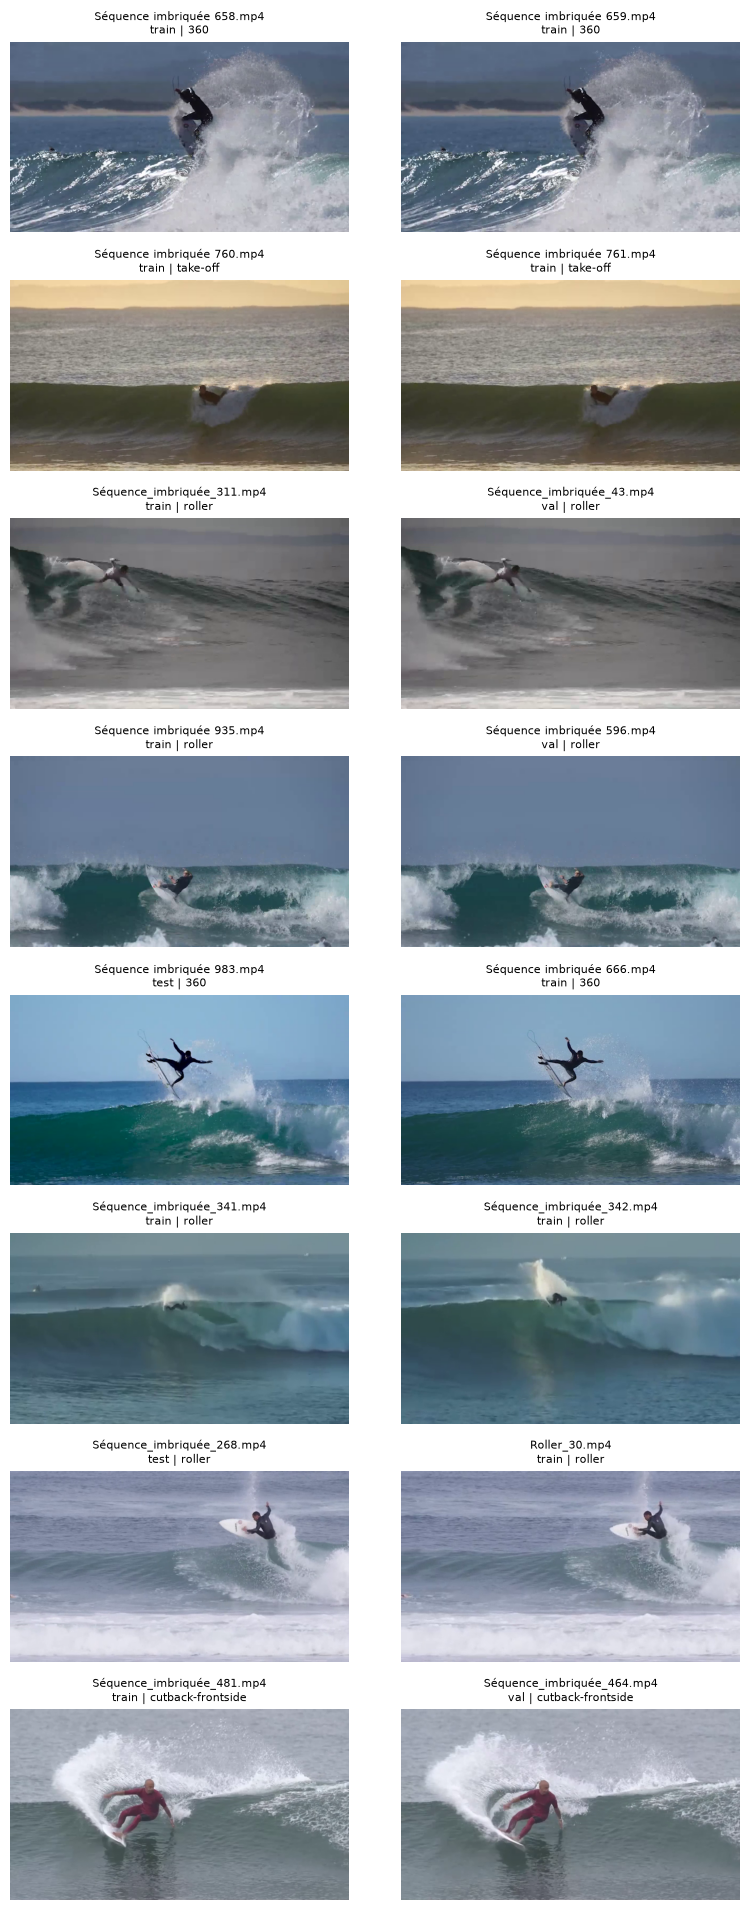

In [14]:
def show_pairs(pairs):
    """Middle frame of both clips of each pair, one pair per row."""
    fig, axes = plt.subplots(len(pairs), 2, figsize=(8, 2.4 * len(pairs)), squeeze=False)
    for row_axes, (_, pair) in zip(axes, pairs.iterrows()):
        for ax, side in zip(row_axes, ["a", "b"]):
            clip = df.loc[pair[f"row_{side}"]]
            ax.imshow(read_frame(clip["path"]))
            ax.set_title(f"{clip['file']}\n{clip['split']} | {clip['maneuver']}", fontsize=8)
            ax.axis("off")
    plt.tight_layout()
    plt.show()

# Pairs that are not byte-identical need a visual check
show_pairs(dups[~dups["identical_file"]])

Findings from the byte-level and visual checks:
- **Label conflicts:** `Séquence_imbriquée_355`, `_357` and `_362` are byte-identical files stored in both `cutback-frontside` and `roller`.
  They will be removed (6 rows), since a single-label classifier cannot learn from contradictory labels.
- **Duplicates:** several pairs show the same frames despite different names (re-exported clips). Five of them cross splits,
  two of them involving the test set, and one links two different sources (`Séquence_imbriquée_268` = `Roller_30`).
  Duplicates are kept but forced into the same group, so both copies always land in the same split.
- **Same wave, different moments:** `Séquence_imbriquée_341` and `_342` are consecutive clips of one wave, a session-level link rather than a duplicate.

> 0.99: 6 pairs
> 0.98: 11 pairs
> 0.97: 27 pairs
> 0.96: 118 pairs
> 0.95: 594 pairs


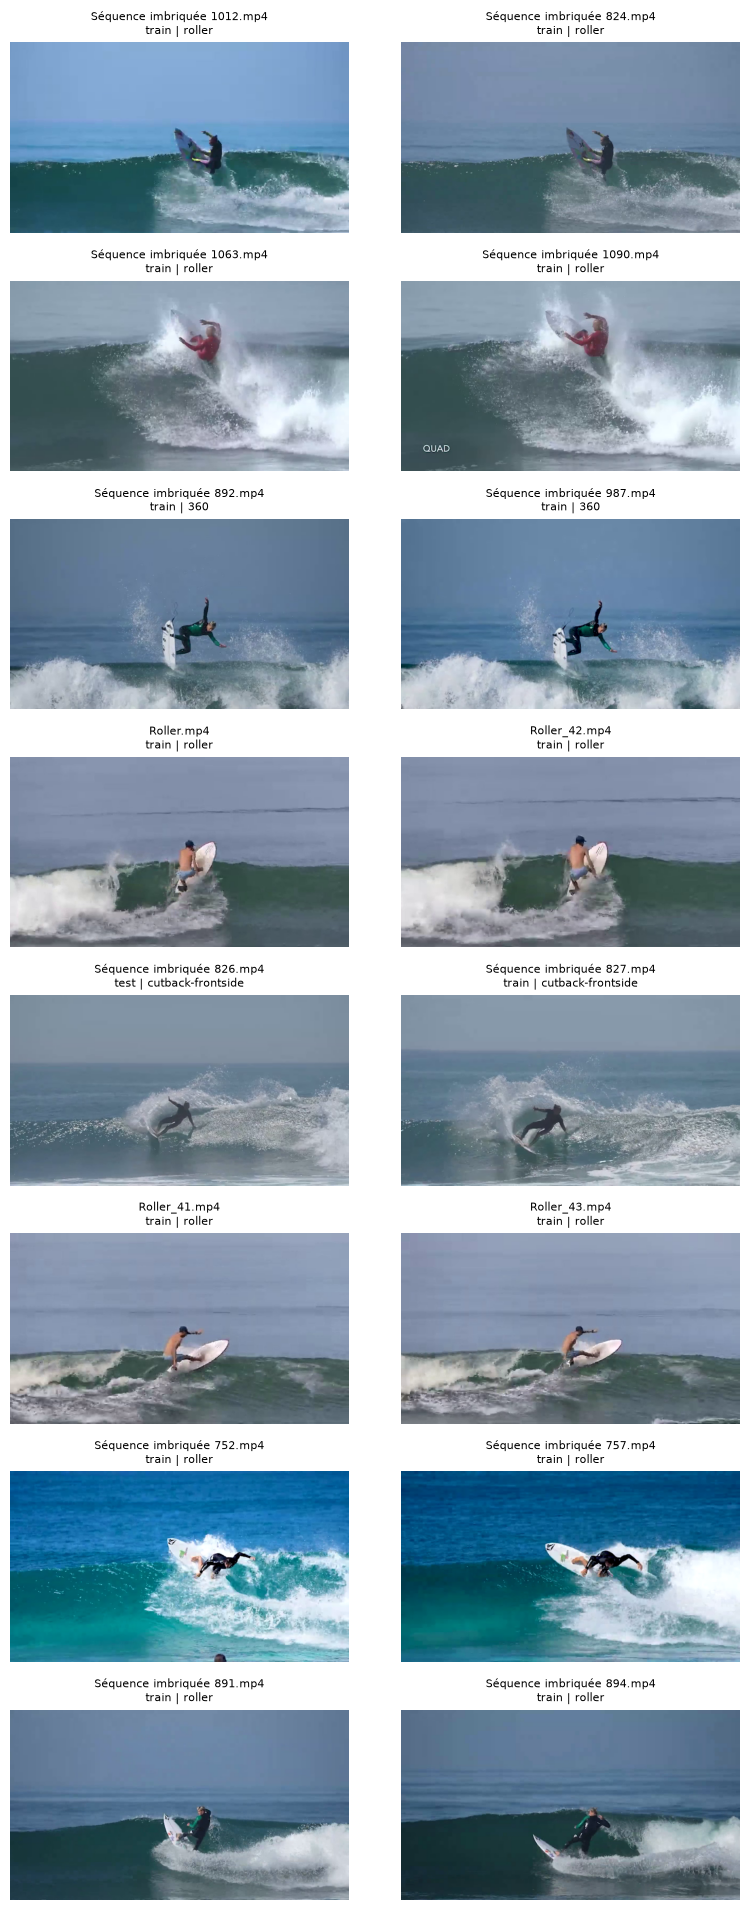

In [15]:
upper = np.triu(sim_matrix, k=1)

# How many pairs remain at lower thresholds? Re-exported duplicates may fall slightly below 0.98
for threshold in [0.99, 0.98, 0.97, 0.96, 0.95]:
    print(f"> {threshold}: {(upper > threshold).sum()} pairs")

# Visual check of the borderline range (0.96 to 0.98)
a, b = np.where((upper > 0.96) & (upper <= 0.98))
borderline = pd.DataFrame({"row_a": a, "row_b": b, "similarity": sim_matrix[a, b].round(4)})
borderline = borderline.sort_values("similarity", ascending=False)
show_pairs(borderline.head(8))

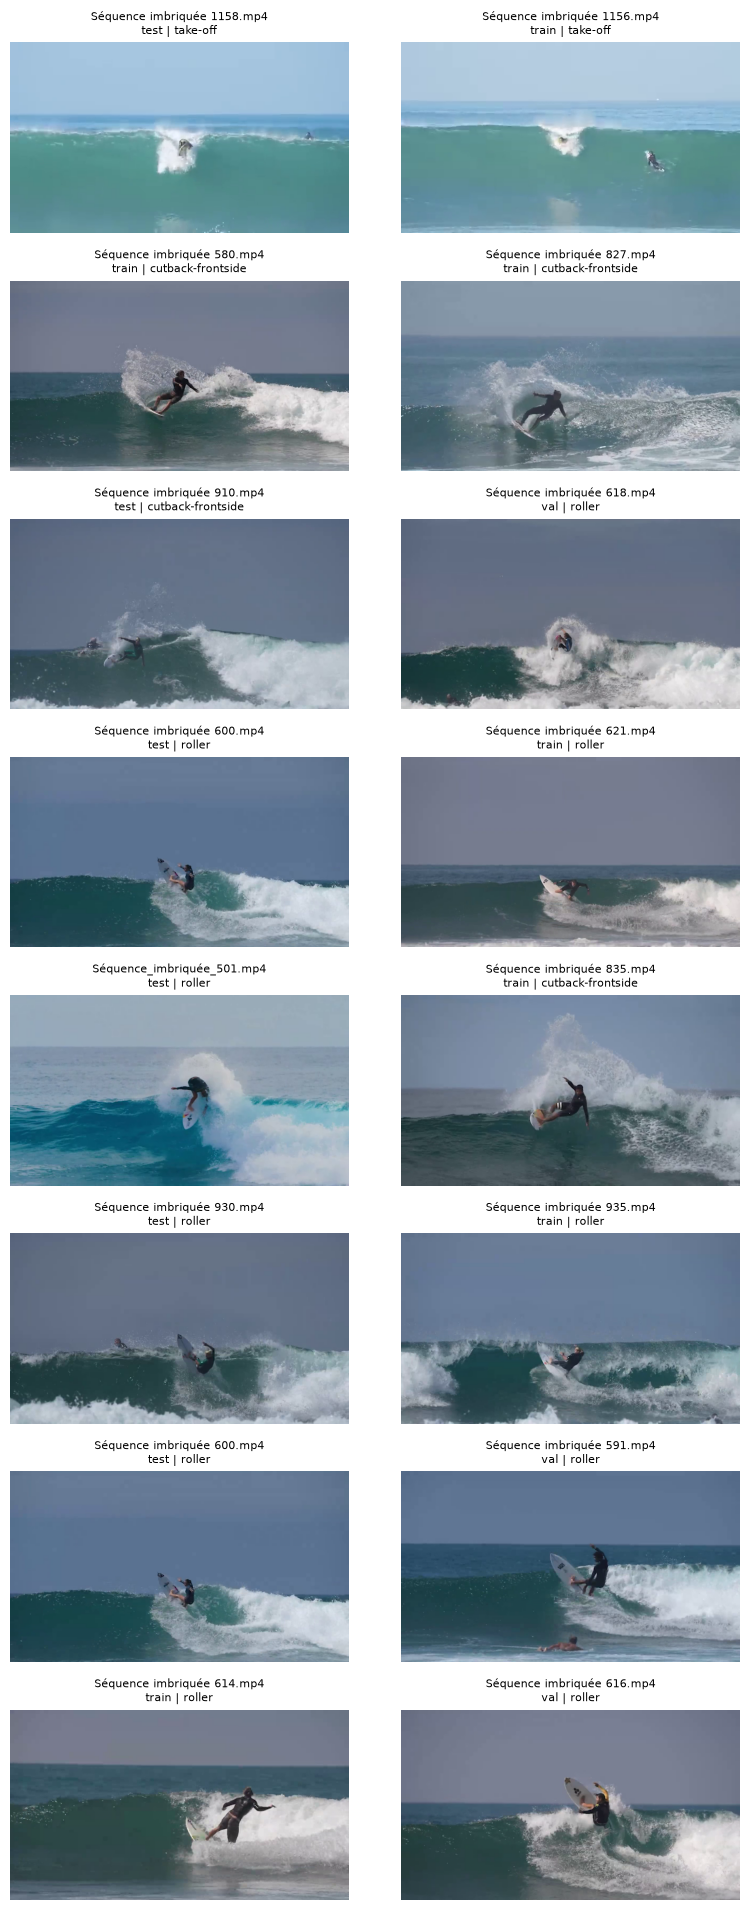

In [16]:
# Bottom of the borderline range: pairs just above 0.96 decide the final threshold
show_pairs(borderline.tail(8))

Between 0.97 and 0.98, every inspected pair is a re-edited duplicate (same frame, different color grading or watermark) or the same wave,
often with distant numbers (e.g. 824 and 1012). Just above 0.96, pairs are mostly different waves from a similar-looking session,
and some are unrelated (`Séquence_imbriquée_501` vs `Séquence imbriquée 835`). The number of pairs grows from 27 above 0.97 to 594 above 0.95.
We therefore link clips with similarity above **0.97** as duplicates or same wave, and rely on contiguous numbering for session-level links.

## 5. Session groups

Clips are linked in two ways:
1. **Contiguous blocks:** within each source, clips ordered by number are cut into blocks of about 25 clips.
   Each cut is moved to the lowest consecutive similarity within ±5 positions, so blocks tend to end at session changes.
2. **Duplicate or same-wave links:** any pair with similarity above 0.97, regardless of source or number.

Groups are the connected components of these links: clips connected directly or through other clips share a group.

In [17]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

BLOCK_SIZE = 25        # target clips per contiguous block
WINDOW = 5             # how far a cut may move to find a session change
LINK_THRESHOLD = 0.97  # duplicate / same-wave similarity

def block_ids(sim_next, block_size=BLOCK_SIZE, window=WINDOW):
    """Block number of each clip in one source, given the similarity of each clip with the next one.

    Nominal cuts every `block_size` clips are moved to the lowest similarity within +-`window`
    positions, so that blocks tend to end where the scene changes.
    """
    n = len(sim_next)
    ids = np.zeros(n, dtype=int)
    for nominal in range(block_size - 1, n - 1, block_size):
        lo, hi = max(0, nominal - window), min(n - 2, nominal + window)
        cut = lo + int(np.nanargmin(sim_next[lo:hi + 1]))   # cut between clip `cut` and `cut + 1`
        ids[cut + 1:] += 1
    return ids

ordered["block"] = ordered.groupby("source")["sim_next"].transform(lambda s: block_ids(s.to_numpy()))
ordered.groupby("source")["block"].nunique()

source
360                     1
roller                  2
sequence_space         26
sequence_underscore    16
Name: block, dtype: int64

In [18]:
# Edges of the graph: consecutive clips inside the same block...
edges = []
for _, block in ordered.groupby(["source", "block"]):
    rows_in_block = block.index.to_numpy()
    edges += list(zip(rows_in_block[:-1], rows_in_block[1:]))

# ...plus duplicate / same-wave pairs anywhere in the dataset
a, b = np.where(upper > LINK_THRESHOLD)
edges += list(zip(a, b))

# Groups = connected components of the graph (one node per clip)
src, dst = np.array(edges).T
graph = coo_matrix((np.ones(len(src)), (src, dst)), shape=(len(df), len(df)))
n_groups, labels = connected_components(graph, directed=False)
df["group"] = labels

sizes = df["group"].value_counts()
print(f"{n_groups} groups; largest: {sizes.max()} clips; singletons: {(sizes == 1).sum()}")
sizes.describe().round(1)

36 groups; largest: 130 clips; singletons: 1


count     36.0
mean      29.5
std       21.2
min        1.0
25%       20.5
50%       25.5
75%       31.0
max      130.0
Name: count, dtype: float64

In [19]:
# Composition of each group: size, sources, original splits and maneuvers
summary = df.groupby("group").agg(
    n_clips=("file", "size"),
    sources=("source", lambda s: ", ".join(sorted(s.unique()))),
    original_splits=("split", lambda s: ", ".join(sorted(s.unique()))),
    maneuvers=("maneuver", "nunique"),
).sort_values("n_clips", ascending=False)

print((summary["original_splits"].str.count(",") > 0).sum(), "of", len(summary),
      "groups were spread over more than one split in the original split")
summary.head(5)

34 of 36 groups were spread over more than one split in the original split


,n_clips,sources,original_splits,maneuvers
group,,,,
6,130,sequence_space,"test, train, val",4
1,54,sequence_space,"test, train, val",4
9,54,sequence_space,"test, train, val",4
14,54,sequence_underscore,"test, train, val",4
18,44,sequence_underscore,"test, train, val",4


## 6. Group-aware split

Label-conflict clips are removed, then clips are split with `StratifiedGroupKFold`:
every group goes entirely to one subset, and each subset keeps roughly the original maneuver proportions.
Target sizes follow the original split: about 70% train, 10% validation and 20% test.

In [20]:
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42

# Remove label conflicts: byte-identical files stored under two different maneuvers
conflicts = dups[dups["identical_file"] & (dups["maneuver_a"] != dups["maneuver_b"])]
conflict_rows = sorted(set(conflicts["row_a"]) | set(conflicts["row_b"]))
clean = df.drop(index=conflict_rows).reset_index(drop=True)
print(len(conflict_rows), "label-conflict rows removed;", len(clean), "clips kept")

# Test: 1 of 5 folds (~20%), whole groups only, maneuver proportions preserved
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(outer.split(clean, clean["maneuver"], groups=clean["group"]))

# Validation: 1 of 8 folds of the remaining clips (~10% of the total)
dev = clean.iloc[dev_idx]
inner = StratifiedGroupKFold(n_splits=8, shuffle=True, random_state=SEED)
train_pos, val_pos = next(inner.split(dev, dev["maneuver"], groups=dev["group"]))

group_split = np.full(len(clean), "train", dtype=object)
group_split[test_idx] = "test"
group_split[dev_idx[val_pos]] = "val"
clean["group_split"] = group_split

6 label-conflict rows removed; 1056 clips kept


In [21]:
# Sanity check: no group may appear in more than one subset
assert clean.groupby("group")["group_split"].nunique().max() == 1, "a group was split!"

# Clips and proportions per subset, compared with the original split
display(pd.crosstab(clean["maneuver"], clean["group_split"], margins=True))
display(pd.DataFrame({
    "original": clean["split"].value_counts(normalize=True),
    "group-aware": clean["group_split"].value_counts(normalize=True),
}).round(3))

group_split,test,train,val,All
maneuver,,,,
360,58,107,15,180
cutback-frontside,47,175,13,235
roller,107,367,46,520
take-off,24,86,11,121
All,236,735,85,1056


,original,group-aware
train,0.696,0.696
test,0.200,0.223
val,0.104,0.080


## 7. Saving the split

The split is saved to `data/splits.csv`, one row per clip, with paths relative to `data/raw/data-split/` so the file works on any machine.
It keeps both the original and the group-aware split, so models can be evaluated on both.

In [22]:
from src.data.inventory import DATA_DIR

SPLITS_FILE = PROJECT_ROOT / "data" / "splits.csv"

splits = pd.DataFrame({
    "clip": clean["path"].map(lambda p: Path(p).relative_to(DATA_DIR).as_posix()),
    "maneuver": clean["maneuver"],
    "group": clean["group"],
    "original_split": clean["split"],
    "split": clean["group_split"],
})
splits.to_csv(SPLITS_FILE, index=False)
print(f"{len(splits)} rows saved to {SPLITS_FILE.relative_to(PROJECT_ROOT)}")
splits.head()

1056 rows saved to data\splits.csv


,clip,maneuver,group,original_split,split
0,test/360/360.mp4,360,0,test,val
1,test/360/Séquence imbriquée 1033.mp4,360,1,test,train
2,test/360/Séquence imbriquée 1165.mp4,360,2,test,train
3,test/360/Séquence imbriquée 1263.mp4,360,3,test,train
4,test/360/Séquence imbriquée 1293.mp4,360,4,test,train


## 8. Findings

- **Label conflicts:** 3 byte-identical clips were stored under both `cutback-frontside` and `roller`; their 6 rows were removed.
- **Duplicates across splits:** re-exported copies of the same clip (same frames, different color grading or watermark) appear in different
  subsets of the original split, including the test set, and across sources (`Séquence_imbriquée_268` = `Roller_30`).
- **Session groups:** contiguous numbering blocks plus duplicate links (similarity > 0.97) give 36 groups, median 25 clips, largest 130.
- **Group-aware split:** 735 / 85 / 236 clips (69.6% / 8.0% / 22.3%), no group shared between subsets, all maneuvers in every subset.
- **Caveats:** the validation set is small (11 take-off and 13 cutback clips), so validation metrics will be noisy;
  360 is over-represented in the test set (32% of its clips). Group k-fold cross-validation can reduce this variance later.